In [1]:
import json
from orderbike.utils import auc_from_metrics_dict
import pandas as pd
import matplotlib.pyplot as plt

/Users/clse/miniforge3/envs/orderbike/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_json(
    "../data/processed/ignored_files/paper/smrainet/coverage_additive_connected/metrics_growth_000.json"
)

In [ ]:
df = df.sort_values(by="xx", axis=0)

KeyError: 'xx'

In [ ]:
df

,xx,coverage,directness,relative_directness,num_cc,length_lcc
0,419.849834,2.511505e+06,1.000000,1.000000,1,419.849834
1,1081.935066,3.532332e+06,0.999919,1.199715,1,1081.935066
2,1710.272824,4.501134e+06,0.999866,1.189175,1,1710.272824
3,2291.961007,5.398016e+06,0.999862,1.194200,1,2291.961007
4,2912.861604,6.355176e+06,0.999164,1.413524,1,2912.861604
...,...,...,...,...,...,...
362,211649.100936,1.744921e+08,0.796978,0.995910,1,211649.100936
363,211921.730913,1.744921e+08,0.796446,0.995433,1,211921.730913
364,212390.127630,1.744921e+08,0.797480,0.996659,1,212390.127630
365,212763.645452,1.744921e+08,0.799615,0.999296,1,212763.645452


In [29]:
res = []
for graph_name in [
    "grid",
    "grid_with_diagonal",
    "three_bridges",
    "radio_concentric",
]:
    for threshold in [5, 10, 20]:
        if threshold == 10:
            folder = f"../data/processed/ignored_files/paper/{graph_name}/adaptive_coverage_additive_connected"
        else:
            folder = f"../data/processed/ignored_files/paper/{graph_name}/adaptive_coverage_additive_connected_{threshold}"
        for i in range(50):
            trial = folder + f"/metrics_growth_{i:03}.json"
            with open(trial, "r") as f:
                met_dict = json.load(f)
                auc_cov = auc_from_metrics_dict(
                    met_dict,
                    "coverage",
                    normalize_y=True,
                    yaxis_method="natural",
                    exp_discounting=False,
                )
                auc_dir = auc_from_metrics_dict(
                    met_dict,
                    "directness",
                    normalize_y=False,
                    max_comparison_y="one",
                    exp_discounting=False,
                )
                auc_reldir = auc_from_metrics_dict(
                    met_dict,
                    "relative_directness",
                    normalize_y=False,
                    exp_discounting=False,
                )
            res.append([graph_name, threshold, i, auc_cov, auc_dir])
df_growth = pd.DataFrame(
    res,
    columns=[
        "Graph",
        "Threshold",
        "Trial",
        "AUC of Coverage",
        "AUC of Directness",
    ],
)

In [46]:
df_growth.groupby(["Graph", "Threshold"])["AUC of Coverage"].mean()

Graph               Threshold
grid                5            0.875555
                    10           0.875693
                    20           0.875759
grid_with_diagonal  5            0.881233
                    10           0.881486
                    20           0.881573
radio_concentric    5            0.843638
                    10           0.843638
                    20           0.845157
three_bridges       5            0.850513
                    10           0.850438
                    20           0.850446
Name: AUC of Coverage, dtype: float64

In [45]:
df_growth.groupby(["Graph", "Threshold"])["AUC of Directness"].mean()

Graph               Threshold
grid                5            0.698929
                    10           0.687049
                    20           0.690054
grid_with_diagonal  5            0.677149
                    10           0.667558
                    20           0.660955
radio_concentric    5            0.725910
                    10           0.726170
                    20           0.712761
three_bridges       5            0.695125
                    10           0.693149
                    20           0.694475
Name: AUC of Directness, dtype: float64

In [44]:
df_growth[(df_growth["Graph"] == "grid") & (df_growth["Threshold"] == 10)][
    "AUC of Directness"
].std()

np.float64(0.005300580787368319)

In [47]:
df_growth.groupby(["Graph", "Threshold"])["AUC of Directness"].std()

Graph               Threshold
grid                5            0.005606
                    10           0.005301
                    20           0.006576
grid_with_diagonal  5            0.005999
                    10           0.011643
                    20           0.013161
radio_concentric    5            0.000811
                    10           0.000693
                    20           0.000905
three_bridges       5            0.002994
                    10           0.001719
                    20           0.002686
Name: AUC of Directness, dtype: float64

In [33]:
df_growth.groupby(["Graph", "Threshold"])["AUC of Directness"].mean()

Graph               Threshold
grid                5            0.698929
                    10           0.687049
                    20           0.690054
grid_with_diagonal  5            0.677149
                    10           0.667558
                    20           0.660955
radio_concentric    5            0.725910
                    10           0.726170
                    20           0.712761
three_bridges       5            0.695125
                    10           0.693149
                    20           0.694475
Name: AUC of Directness, dtype: float64

In [7]:
df_growth.groupby("Threshold")["AUC of Coverage"].mean()

Threshold
5     0.875555
10    0.875693
20    0.875759
Name: AUC of Coverage, dtype: float64

In [16]:
df_growth.groupby("Threshold")["AUC of Directness"].std()

Threshold
5     0.005606
10    0.005301
20    0.006576
Name: AUC of Directness, dtype: float64

In [8]:
df_growth.groupby("Threshold")["AUC of Directness"].mean()

Threshold
5     0.698929
10    0.687049
20    0.690054
Name: AUC of Directness, dtype: float64

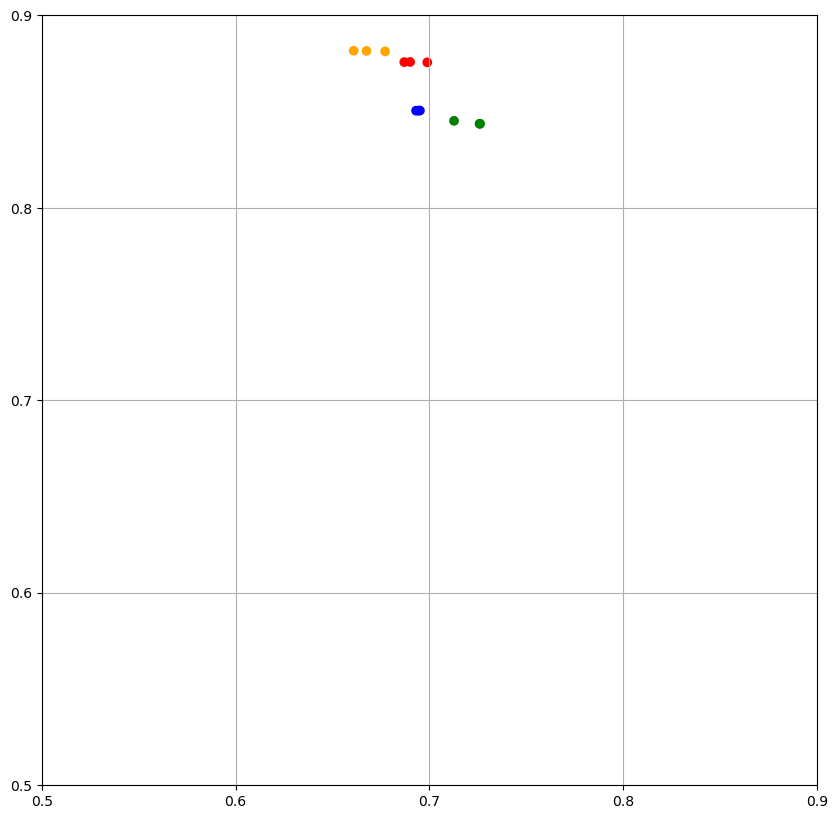

In [39]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(
    x=df_growth.groupby(["Graph", "Threshold"])["AUC of Directness"].mean(),
    y=df_growth.groupby(["Graph", "Threshold"])["AUC of Coverage"].mean(),
    c=["red"] * 3 + ["orange"] * 3 + ["green"] * 3 + ["blue"] * 3,
    # yerr=df_growth.groupby(["Graph", "Threshold"])["AUC of Coverage"].std(),
    # xerr=df_growth.groupby(["Graph", "Threshold"])["AUC of Directness"].std(),
    # fmt="o",
    # barsabove=True,
)
ax.set_xlim([0.5, 0.9])
ax.set_ylim([0.5, 0.9])
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9])
ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9])
ax.grid()